# Scientific ML vs Conventional ML for Seismic **Faults/discontinuity** Detection — F3, Netherlands

Extension of *"Deep learning for three-dimensional seismic fault prediction using convolutional neural networks"* (Bashir et al.), original code <https://github.com/dryasir/CNN-Fault-Prediction>.

### What is compared

| | **Conventional ML** (original workflow) | **Scientific ML (SciML)** |
|---|---|---|
| Training data | A few hand-interpreted sections of the target survey (5 train + 1 validation inline) | **Physics-based synthetic seismic**: layered earth → folding → faulting → convolution with a wavelet matched to the measured F3 spectrum → noise. Labels are exact. |
| Fault / no-fault examples | Only patches that contain a fault (`threshold = 0`) | Patches **with and without** faults (folds, unconformities, noise = "not fault") |
| Amplitude scaling | Global min–max to [0, 1] | Local-RMS (AGC) — removes depth-dependent amplitude, same for synthetic and real |
| Network / loss | U-Net, binary cross-entropy, accuracy | U-Net + batch-norm, class-weighted cross-entropy + Dice (handles ~2 % fault pixels) |
| Prediction | Tiles averaged, threshold 0.5 | Gaussian-weighted sliding window, Monte-Carlo dropout **uncertainty** |
| Labels needed | Yes | **No** (optionally fine-tuned on the same labelled inlines → "SciML + fine-tune") |

### How the comparison is made fair
F3 has no complete fault interpretation, so accuracy cannot be measured on F3 itself. We therefore build a **benchmark survey with exact ground truth** whose seismic character comes from F3: it is convolved with the **statistical wavelet extracted from F3** and contaminated with F3-coloured noise. The SciML network never sees this wavelet, this noise or this geology during training. Both methods get the same 5 labelled training inlines + 1 validation inline (exactly the paper's set-up) and are scored on **held-out inlines** that are at least `BENCH_TEST_BUFFER` inlines away from any labelled one (no spatial leakage). Finally both models are applied to real F3 (§12). If you later provide fault masks for F3 (`LABEL_DIR`), §12 also scores both methods on a held-out F3 inline.

**Map:** 0 Config · 1 Setup · 2 F3 data · 3 Physics-based generator · 4 How SciML trains (fault / no-fault) · 5 Benchmark survey · 6 Conventional ML · 7 SciML · 8 Predictions · 9 Quantitative comparison · 10 Confusion matrices · 11 Where SciML improves · 12 F3 application · 13 Volume & export

## 0. Configuration

In [1]:
import os

# ---------------- general ----------------
MODE            = "2D"          # SciML network: "2D" or "3D" (the conventional baseline is 2D, as in the paper)
QUICK_TEST      = False         # True -> tiny sizes to check the pipeline on a CPU in minutes
SEED            = 42
RUN_ROOT        = "runs"
CLASS_NAME      = "Faults/discontinuity"

# ---------------- F3 data ----------------
SEGY_PATH       = r"E:\F03 Demo data\1 Seismic\Seismic_F03-002.sgy"   # None -> synthetic demo "field" volume
IL_BYTE, XL_BYTE = 21, 25       # Seismic_F03-002.sgy stores inline/crossline in bytes 21/25 (rev1 standard: 189/193)
MUTE_FRACTION   = 0.02          # water-column mute: samples above first |amp| > MUTE_FRACTION * trace max
EDGE_MARGIN     = 6             # ignore predictions this close to muted / dead data
# optional F3 fault masks (PNG, faults painted in the alpha channel) -> F3 is scored too
LABEL_DIR       = None
LABEL_PATTERN   = "mask_inline_{}.png"
LABEL_INDEXING  = "inline_number"   # "inline_number" (header value) or "index" (array index, as in the original notebook)
LABELED_INLINES = []            # e.g. [100, 200, 300, 400, 500, 600]
VAL_INLINES     = []            # e.g. [300]
TEST_INLINES    = []            # e.g. [600]   (held out, never used for training or thresholds)

# ---------------- physics-based synthetic data (SciML) ----------------
N_SYNTH_TRAIN_2D, N_SYNTH_VAL_2D = 3000, 300
N_SYNTH_TRAIN_3D, N_SYNTH_VAL_3D = 300, 40
FAULT_THROW     = (3.5, 15.0)   # samples
FRACTURE_THROW  = (1.5, 3.5)    # samples (small-offset discontinuities, also labelled Faults/discontinuity)
WAVELET_FREQ    = (0.09, 0.22)  # Ricker peak frequency, cycles/sample (F3: 42 Hz @ 4 ms = 0.17)
P_NO_FAULT      = 0.2           # fraction of synthetic samples with no fault at all ("not fault" examples)
LABEL_DILATE    = 1             # label thickness (+/- pixels), used for every method and for scoring

# ---------------- benchmark survey with exact ground truth ----------------
BENCH_SHAPE     = (256, 72, 448)    # (time, inline, crossline)
BENCH_SNR       = 4.0
BENCH_N_FAULTS, BENCH_N_FRACTURES = 5, 10
BENCH_STRIKE_SPREAD = 35        # degrees: fault strikes within +/- this of perpendicular to the inlines (survey shot across the fault trend)
BENCH_N_LABELED = 6             # labelled inlines (5 train + 1 validation, as in the paper)
BENCH_TEST_BUFFER = 4           # test inlines must be > this many inlines from a labelled one

# ---------------- conventional ML (original workflow) ----------------
CONV_PATCH      = 64
CONV_N_TRAIN, CONV_N_VAL = 8000, 2000
CONV_THRESHOLD_PIX = 0          # keep only patches with > this many fault pixels (original: 0)
CONV_EPOCHS     = 15            # original notebook: 5 (we allow more + keep the best validation epoch)
CONV_BATCH      = 32
CONV_DT         = 16            # tile step for prediction (original: 16)
PRETRAINED_CONV_MODEL = None

# ---------------- SciML network ----------------
PATCH_2D, PATCH_3D = 128, 64
DEPTH_2D, DEPTH_3D = 4, 3
BASE_FILTERS    = 16
DROPOUT         = 0.15
EPOCHS          = 20
BATCH_2D, BATCH_3D = 16, 4
LR              = 1e-3
DICE_WEIGHT     = 1.0
FINETUNE        = True          # also report "SciML + fine-tune" on the same labelled inlines
FINETUNE_EPOCHS, FINETUNE_LR, N_FT_PATCHES = 8, 2e-4, 1500
POS_FRACTION    = 0.6
PRETRAINED_MODEL = None         # path to a saved SciML .keras model -> skip synthetic training
PRETRAINED_FT_MODEL = None      # path to a saved fine-tuned SciML model -> skip fine-tuning

# ---------------- inference / F3 ----------------
OVERLAP         = 0.5
MC_SAMPLES      = 10
PREDICT_INLINE  = 462           # F3 inline shown in §12 (crosses the salt dome)
CROP_3D         = dict(il=(410, 514), xl=(125, 1300), t=(0, None))   # header numbers; volume prediction in §13
PREDICT_VOLUME  = True          # §13: predict CROP_3D (2D model: inline sweep; 3D model: full 3D)
EXPORT_SEGY     = True

# ---- optional overrides (automated testing), e.g. SCIML_OVERRIDES='{"MODE": "3D"}'
import json as _json
globals().update(_json.loads(os.environ.get("SCIML_OVERRIDES", "{}")))

if QUICK_TEST:
    N_SYNTH_TRAIN_2D, N_SYNTH_VAL_2D, N_SYNTH_TRAIN_3D, N_SYNTH_VAL_3D = 96, 16, 16, 4
    BENCH_SHAPE, BENCH_TEST_BUFFER = (96, 40, 160), 2
    CONV_N_TRAIN, CONV_N_VAL, CONV_EPOCHS = 300, 100, 2
    PATCH_2D, PATCH_3D, DEPTH_2D, DEPTH_3D, BASE_FILTERS = 64, 32, 3, 2, 8
    EPOCHS, FINETUNE_EPOCHS, N_FT_PATCHES, MC_SAMPLES = 2, 1, 64, 3

assert MODE in ("2D", "3D")
NDIM  = 2 if MODE == "2D" else 3
PATCH = PATCH_2D if NDIM == 2 else PATCH_3D
DEPTH = DEPTH_2D if NDIM == 2 else DEPTH_3D
BATCH = BATCH_2D if NDIM == 2 else BATCH_3D
assert PATCH % 2 ** DEPTH == 0
print(f"MODE={MODE} PATCH={PATCH} QUICK_TEST={QUICK_TEST}")

MODE=2D PATCH=128 QUICK_TEST=False


## 1. Setup
Requires TensorFlow ≥ 2.16 (Keras 3): `pip install "tensorflow>=2.16" segyio scipy scikit-image scikit-learn matplotlib pandas`

In [2]:
import json, time, shutil, itertools, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from PIL import Image
import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.metrics import precision_recall_curve, average_precision_score
try:
    import segyio
except ImportError:
    segyio = None

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s); keras.utils.set_random_seed(s)
set_seed(SEED)
for g in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(g, True)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

RUN_DIR = os.path.join(RUN_ROOT, time.strftime("%Y%m%d-%H%M%S") + f"_{MODE}")
os.makedirs(RUN_DIR, exist_ok=True)
CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, list, tuple, dict, bool, type(None)))}
json.dump(CONFIG, open(os.path.join(RUN_DIR, "config.json"), "w"), indent=2, default=str)
print("Run folder:", RUN_DIR)

def savefig(name):
    plt.savefig(os.path.join(RUN_DIR, name), dpi=130, bbox_inches="tight")

# colours used throughout
C_CONV, C_SCIML, C_FT, C_BASE = "#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"

I0000 00:00:1795180963.128633    2688 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795180963.171479    2688 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795180964.456674    2688 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPUs: []
Run folder: runs/20261120-162245_2D


## 2. F3 seismic data
SEG-Y read trace-by-trace onto the (inline, crossline, time) grid using the trace headers. Then:
* **Water-column mute** and **dead-trace** detection (no predictions there).
* **Statistical wavelet** from the average F3 amplitude spectrum (zero-phase) — used to give the benchmark survey F3 character (§5).
* Two amplitude versions: **global min–max** (conventional workflow) and **local-RMS / AGC** (SciML).

In [3]:
def load_segy(path, il_byte=IL_BYTE, xl_byte=XL_BYTE):
    with segyio.open(path, "r", ignore_geometry=True) as f:
        f.mmap()
        ils = np.asarray(f.attributes(il_byte)[:]); xls = np.asarray(f.attributes(xl_byte)[:])
        il_vals, xl_vals = np.unique(ils), np.unique(xls)
        vol = np.zeros((len(il_vals), len(xl_vals), len(f.samples)), np.float32)
        vol[np.searchsorted(il_vals, ils), np.searchsorted(xl_vals, xls)] = segyio.tools.collect(f.trace[:])
        dt_ms = segyio.tools.dt(f) / 1000.0
    return vol, dict(il_vals=il_vals, xl_vals=xl_vals, dt_ms=dt_ms)

def local_rms_normalize(x, win=31, clip=4.0):
    rms = np.sqrt(ndi.uniform_filter(x.astype(np.float32) ** 2, size=win, mode="reflect")) + 1e-6
    rms = np.maximum(rms, 0.05 * np.median(rms))
    return np.clip(x / rms, -clip, clip).astype(np.float32)

def estimate_wavelet(traces, n=81):
    # zero-phase statistical wavelet from the mean amplitude spectrum of the traces (n_traces, n_samples)
    ns = traces.shape[-1]
    spec = np.abs(np.fft.rfft(traces * np.hanning(ns), axis=-1)).mean(0)
    w = np.fft.fftshift(np.fft.irfft(spec, n=ns))
    c = ns // 2; w = w[c - n // 2: c + n // 2 + 1] * np.hanning(n)
    return (w / np.abs(w).max()).astype(np.float32), spec

def ormsby(f1, f2, f3, f4, n=81, dt=0.004):
    t = (np.arange(n) - n // 2) * dt
    def p(f): return (np.pi * f) ** 2 * np.sinc(f * t) ** 2
    w = (p(f4) - p(f3)) / (f4 - f3) - (p(f2) - p(f1)) / (f2 - f1)
    return (w / np.abs(w).max()).astype(np.float32)

## 3. Physics-based synthetic seismic (the "scientific" part of SciML)
Each training sample is generated by a geological + wave-physics forward model, so its label is exact:

1. **Layered earth** — random layer thicknesses and impedances, reflectivity $r=\tfrac12\Delta\ln Z$.
2. **Folding** — vertical shift field $s(x,y,t)$ (Gaussian folds growing with depth + planar dip): $\tau=t+s$.
3. **Unconformity** (random) — erosional surface with a differently dipping sequence above (a *non-fault* discontinuity: label 0).
4. **Faulting** — planar faults (random strike, dip 55–85°, throw, elliptical throw taper); the hanging wall is displaced along the dip vector $\mathbf u$: $R'(\mathbf p)=R(\mathbf p-d(\mathbf p)\,\mathbf u)$. Large-throw faults and small-throw fractures are both labelled **Faults/discontinuity**.
5. **Convolution** $s = w * R$ (Ricker with F3-matched peak frequency, or any given wavelet) + band-limited noise, random polarity.

`P_NO_FAULT` of the samples contain **no fault at all**, so the network also learns what is *not* a fault (folds, unconformities, noise).

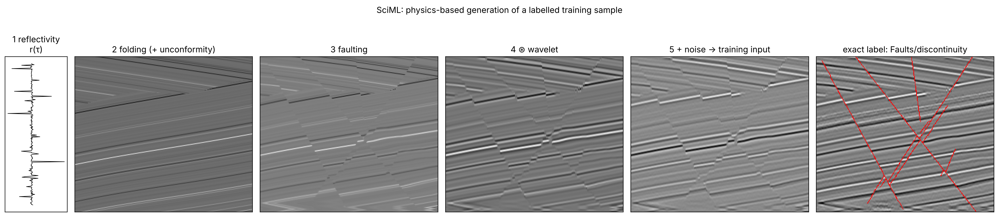

In [4]:
def ricker(f, n=None):
    n = n or 2 * int(1.5 / f) + 1
    t = np.arange(n) - n // 2; a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def random_reflectivity(n, rng):
    thick = rng.exponential(rng.uniform(3, 8), size=n).astype(int) + 1
    z = np.cumsum(rng.normal(0, 1, size=len(thick))) * 0.08 + 1.0
    imp = np.repeat(np.exp(z), thick)[:n]
    if len(imp) < n: imp = np.pad(imp, (0, n - len(imp)), mode="edge")
    r = np.zeros(n); r[1:] = 0.5 * np.diff(np.log(imp)); r += rng.normal(0, 0.002, n)
    return r / (np.abs(r).max() + 1e-9)

def synth_seismic(shape, rng, wavelet=None, snr=None, normalize=True, n_faults=None, n_fractures=None,
                  p_unconformity=0.35, p_no_fault=P_NO_FAULT, return_stages=False, strike_spread=None):
    # shape (nt, nx) or (nt, nx, ny). Returns seismic x and label dict (uint8): fault, fracture, unconformity, target
    nd = len(shape); nt = shape[0]
    grids = np.meshgrid(*[np.arange(s, dtype=np.float32) for s in shape], indexing="ij")
    t = grids[0]; lat = grids[1:]; L = float(max(shape[1:]))
    stages = {}

    def layered(rng):
        pad = int(2.5 * nt); r = random_reflectivity(nt + 2 * pad, rng)
        s = np.zeros(shape, np.float32)
        for _ in range(rng.integers(1, 5)):
            c = [rng.uniform(0, n) for n in shape[1:]]; sig = rng.uniform(0.15, 0.6) * L
            g = np.exp(-sum((l - ci) ** 2 for l, ci in zip(lat, c)) / (2 * sig ** 2))
            s += rng.uniform(-1, 1) * rng.uniform(4, 16) * g * (1.5 * t / nt)
        s += rng.uniform(-8, 8) + sum(rng.uniform(-0.25, 0.25) * l for l in lat)
        return np.interp((t + s + pad).ravel(), np.arange(len(r)), r).reshape(shape).astype(np.float32), r[pad:pad + nt]

    refl, r1d = layered(rng)
    lab = {c: np.zeros(shape, np.uint8) for c in ("fault", "fracture", "unconformity")}
    if rng.random() < p_unconformity:
        refl2, _ = layered(rng)
        tu = rng.uniform(0.2, 0.6) * nt + sum(rng.uniform(-0.15, 0.15) * l for l in lat) \
             + rng.uniform(2, 6) * np.sin(2 * np.pi * lat[0] / rng.uniform(0.5, 2) / L + rng.uniform(0, 6))
        refl = np.where(t < tu, refl2, refl)
        lab["unconformity"] = (np.abs(t - tu) < 0.5).astype(np.uint8)
    stages["reflectivity_1d"] = r1d; stages["folded"] = refl.copy()

    no_fault = n_faults is None and n_fractures is None and rng.random() < p_no_fault
    nf = (0 if no_fault else rng.integers(1, 5)) if n_faults is None else n_faults
    nfr = (0 if no_fault else rng.integers(0, 9)) if n_fractures is None else n_fractures
    events = [("fault", FAULT_THROW)] * nf + [("fracture", FRACTURE_THROW)] * nfr
    rng.shuffle(events)
    coords = np.stack([g.ravel() for g in grids])
    for kind, (dmin, dmax) in events:
        theta = np.deg2rad(rng.uniform(55, 85))
        if nd == 2:
            phi = rng.choice([0.0, np.pi]) + rng.normal(0, 0.15)
        elif strike_spread is None:
            phi = rng.uniform(0, 2 * np.pi)
        else:   # fault normal within +/- strike_spread of the crossline axis -> faults cross inlines steeply
            phi = rng.choice([np.pi / 2, -np.pi / 2]) + rng.uniform(-strike_spread, strike_spread)
        if nd == 2:
            n_vec = np.array([np.cos(theta), np.sin(theta) * np.cos(phi)])
            u_vec = np.array([-np.sin(theta), np.cos(theta) * np.cos(phi)])
        else:
            n_vec = np.array([np.cos(theta), np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi)])
            u_vec = np.array([-np.sin(theta), np.cos(theta) * np.cos(phi), np.cos(theta) * np.sin(phi)])
        n_vec /= np.linalg.norm(n_vec); u_vec -= n_vec * (u_vec @ n_vec); u_vec /= np.linalg.norm(u_vec)
        p0 = np.array([rng.uniform(0.15, 0.85) * s for s in shape])
        throw = rng.uniform(dmin, dmax) * (1 if rng.random() < 0.8 else -1)
        R = rng.uniform(0.7, 2.0) * L if kind == "fault" else rng.uniform(6, 0.35 * L + 6)
        q = coords - p0[:, None]; dist = n_vec @ q
        inplane = np.sqrt(np.maximum((q ** 2).sum(0) - dist ** 2, 0))
        d = throw * np.clip(1 - (inplane / R) ** 2, 0, None)
        src = coords - ((dist > 0) * d)[None, :] * u_vec[:, None]
        refl = ndi.map_coordinates(refl, src, order=1, mode="mirror").reshape(shape)
        for c in lab:
            lab[c] = ndi.map_coordinates(lab[c], src, order=0, mode="constant", cval=0).reshape(shape)
        lab[kind][((np.abs(dist) < 0.5) & (np.abs(d) > 0.5)).reshape(shape)] = 1
    stages["faulted"] = refl.copy()

    w = ricker(rng.uniform(*WAVELET_FREQ)) if wavelet is None else wavelet
    x = ndi.convolve1d(refl, w, axis=0, mode="reflect"); stages["convolved"] = x.copy()
    noise = ndi.convolve1d(rng.normal(0, 1, shape), w, axis=0, mode="reflect")
    if nd > 1: noise = ndi.gaussian_filter(noise, [0] + [rng.uniform(0, 1.0)] * (nd - 1))
    snr = rng.uniform(2, 20) if snr is None else snr
    x = x + noise * (x.std() / (noise.std() + 1e-9)) / snr
    if wavelet is None: x *= rng.choice([-1, 1])
    stages["noisy"] = x.copy()
    if normalize: x = local_rms_normalize(x)
    lab["target"] = np.maximum(lab["fault"], lab["fracture"])
    return (x, lab, stages) if return_stages else (x, lab)

def dilate2d(m, n=LABEL_DILATE):
    return ndi.binary_dilation(m > 0, iterations=n).astype(np.uint8) if n > 0 else (m > 0).astype(np.uint8)

# ---- figure: how one SciML training sample is built ----
rng = np.random.default_rng(SEED + 5)
x, lb, st = synth_seismic((PATCH_2D * 2, PATCH_2D * 2), rng, n_faults=3, n_fractures=4, p_unconformity=1.0, return_stages=True)
fig, ax = plt.subplots(1, 6, figsize=(20, 4.2), gridspec_kw=dict(width_ratios=[0.35, 1, 1, 1, 1, 1]))
ax[0].plot(st["reflectivity_1d"], np.arange(len(st["reflectivity_1d"])), "k", lw=0.7); ax[0].invert_yaxis()
ax[0].set_title("1 reflectivity\nr(τ)")
for a, k, ttl in zip(ax[1:5], ["folded", "faulted", "convolved", "noisy"],
                     ["2 folding (+ unconformity)", "3 faulting", "4 ⊛ wavelet", "5 + noise → training input"]):
    a.imshow(st[k], cmap="gray", aspect="auto"); a.set_title(ttl)
ax[5].imshow(x, cmap="gray", aspect="auto")
ax[5].imshow(np.ma.masked_equal(lb["target"], 0), cmap="autumn", aspect="auto", interpolation="none")
ax[5].set_title(f"exact label: {CLASS_NAME}")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.suptitle("SciML: physics-based generation of a labelled training sample", y=1.02); plt.tight_layout()
savefig("fig_sciml_forward_model.png"); plt.show()

## 4. How SciML trains: fault and no-fault examples
The synthetic library is cut into patches. Unlike the conventional workflow (only patches that contain a fault, `threshold = 0`), the SciML library contains **fault patches and no-fault patches**, so the network learns both what a fault is and what it is not. The figure uses the same layout as the original notebook (seismic patch on top, label mask below).

SciML synthetic library: train (16, 128, 128, 1), val (300, 128, 128, 1) (4s)
  fault patches: 75%   no-fault patches: 25%   fault pixels: 6.90%


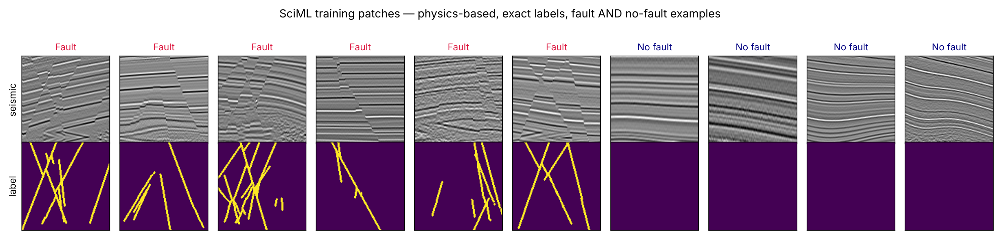

In [5]:
def make_synth_set(n, seed):
    rng = np.random.default_rng(seed)
    shape = (PATCH,) * NDIM
    X = np.zeros((n,) + shape + (1,), np.float32); Y = np.zeros((n,) + shape + (1,), np.int8)
    for i in range(n):
        x, lb = synth_seismic(shape, rng)
        X[i, ..., 0] = x
        Y[i, ..., 0] = ndi.binary_dilation(lb["target"] > 0, iterations=LABEL_DILATE) if LABEL_DILATE else lb["target"]
    return X, Y

t0 = time.time()
nS_tr, nS_va = (N_SYNTH_TRAIN_2D, N_SYNTH_VAL_2D) if NDIM == 2 else (N_SYNTH_TRAIN_3D, N_SYNTH_VAL_3D)
Xs_tr, Ys_tr = make_synth_set(nS_tr, SEED + 1)
Xs_va, Ys_va = make_synth_set(nS_va, SEED + 2)
has_fault = Ys_tr.reshape(len(Ys_tr), -1).max(1) > 0
print(f"SciML synthetic library: train {Xs_tr.shape}, val {Xs_va.shape} ({time.time() - t0:.0f}s)")
print(f"  fault patches: {has_fault.mean():.0%}   no-fault patches: {(~has_fault).mean():.0%}   "
      f"fault pixels: {(Ys_tr == 1).mean():.2%}")

def mid(a):   # 2D view of a 2D/3D patch
    return a if a.ndim == 2 else a[:, a.shape[1] // 2]

# original-notebook style figure (2 x 10): 6 fault patches + 4 no-fault patches
idx_f = np.where(has_fault)[0][:6]; idx_n = np.where(~has_fault)[0][:4]
sel = list(idx_f) + list(idx_n)
fig, axs = plt.subplots(2, len(sel), figsize=(15, 3.4))
for m, k in enumerate(sel):
    axs[0, m].imshow(mid(Xs_tr[k, ..., 0]), interpolation="spline16", cmap=plt.cm.gray, aspect=1)
    axs[0, m].set_title("Fault" if has_fault[k] else "No fault", color="crimson" if has_fault[k] else "navy", fontsize=10)
    axs[1, m].imshow(mid(Ys_tr[k, ..., 0]), interpolation="spline16", aspect=1, vmin=0, vmax=1)
    for a in axs[:, m]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel("seismic"); axs[1, 0].set_ylabel("label")
plt.suptitle("SciML training patches — physics-based, exact labels, fault AND no-fault examples", y=1.03)
plt.tight_layout(); savefig("fig_sciml_training_patches.png"); plt.show()

## 5. Benchmark survey with exact ground truth (F3 character)
A 3D survey generated with the **F3 statistical wavelet** (§2) and F3-coloured noise at `BENCH_SNR`, with its own random geology (fault strikes within ±`BENCH_STRIKE_SPREAD`° of perpendicular to the inlines, as in a survey shot across the fault trend; inlines see *apparent* dips). The SciML network was trained on Ricker wavelets only, so this is a genuine domain shift. Six inlines are "interpreted" (5 train + 1 validation, as in the paper); test inlines are held out with a spatial buffer.

F3 loaded: (n_il, n_xl, n_t) = (105, 1176, 645), dt = 4.0 ms


dead traces 0.1%, median mute 12 samples, SciML volume (645, 105, 1176)


benchmark (256, 72, 448): train inlines [4, 17, 29, 54, 67], validation [42], 18 held-out test inlines
fault pixels in test inlines: 6.20%


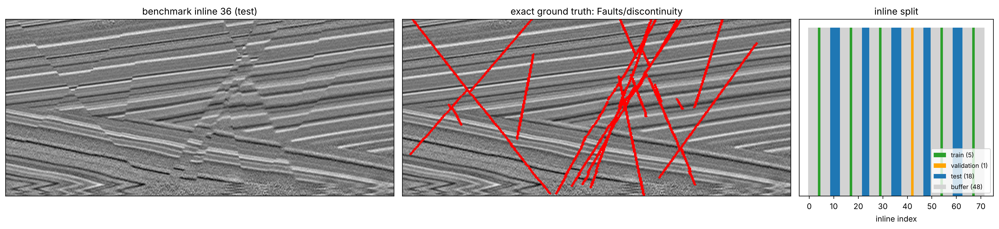

In [6]:
F3_WAVELET = None
if SEGY_PATH:
    assert segyio is not None, "pip install segyio"
    RAW, GEOM = load_segy(SEGY_PATH)
    print(f"F3 loaded: (n_il, n_xl, n_t) = {RAW.shape}, dt = {GEOM['dt_ms']} ms")
    flat = RAW.reshape(-1, RAW.shape[2])
    smp = flat[np.random.default_rng(0).choice(len(flat), min(8000, len(flat)), replace=False)]
    F3_WAVELET, F3_SPEC = estimate_wavelet(smp[np.abs(smp).sum(1) > 0])
    REAL_TRUTH = None
else:
    print("No SEGY_PATH -> synthetic demo 'field' volume (with its exact faults as F3 stand-in)")
    demo = synth_seismic((192, 96, 256) if not QUICK_TEST else (96, 48, 128), np.random.default_rng(SEED + 7),
                         normalize=False, n_faults=5, n_fractures=12, p_unconformity=1.0, strike_spread=np.deg2rad(35))
    RAW = demo[0].transpose(1, 2, 0).copy(); REAL_TRUTH = demo[1]["target"]
    GEOM = dict(il_vals=np.arange(RAW.shape[0]) + 100, xl_vals=np.arange(RAW.shape[1]) + 300, dt_ms=4.0)
    LABEL_INDEXING = "index"; PREDICT_INLINE = RAW.shape[0] // 2
    CROP_3D = dict(il=(None, None), xl=(None, None), t=(0, None))

# water-column mute, dead traces, safe prediction zone
amax = np.abs(RAW).max(-1); DEAD = amax == 0
FIRST = np.where(DEAD, RAW.shape[2], np.argmax(np.abs(RAW) > MUTE_FRACTION * amax[..., None], axis=-1))
FIRST_SAFE = ndi.maximum_filter(FIRST, size=2 * EDGE_MARGIN + 1, mode="nearest") + EDGE_MARGIN
RAW[np.arange(RAW.shape[2])[None, None, :] < FIRST[..., None]] = 0
F3_MIN, F3_MAX = float(RAW.min()), float(RAW.max())
VOL = local_rms_normalize(RAW.transpose(2, 0, 1))          # SciML input (t, il, xl)
NT, NIL, NXL = VOL.shape
print(f"dead traces {DEAD.mean():.1%}, median mute {np.median(FIRST[~DEAD]):.0f} samples, SciML volume {VOL.shape}")

def f3_conv_section(k):   # original workflow: global min-max to [0, 1], (t, xl)
    return (RAW[k].T - F3_MIN) / (F3_MAX - F3_MIN)

def f3_valid_section(k):  # (t, xl) bool: below mute and away from dead traces
    return np.arange(NT)[:, None] >= FIRST_SAFE[k][None, :]

def il_to_index(n):
    return int(np.searchsorted(GEOM["il_vals"], n)) if LABEL_INDEXING == "inline_number" else int(n)

# ---------------- benchmark survey ----------------
BENCH_WAVELET = F3_WAVELET if F3_WAVELET is not None else ormsby(8, 12, 50, 70)
xb, lb = synth_seismic(BENCH_SHAPE, np.random.default_rng(SEED + 1000), wavelet=BENCH_WAVELET, snr=BENCH_SNR,
                       normalize=False, n_faults=BENCH_N_FAULTS, n_fractures=BENCH_N_FRACTURES, p_unconformity=1.0,
                       strike_spread=np.deg2rad(BENCH_STRIKE_SPREAD))
BENCH_RAW = xb                                             # (t, il, xl)
s2 = ndi.generate_binary_structure(2, 1); s3 = np.zeros((3, 3, 3), bool); s3[:, 1, :] = s2   # dilate within inlines
BENCH_TRUTH = (ndi.binary_dilation(lb["target"] > 0, s3, iterations=LABEL_DILATE) if LABEL_DILATE else lb["target"] > 0).astype(np.uint8)
BENCH_VOL = local_rms_normalize(BENCH_RAW)                 # SciML conditioning
BENCH_MINMAX = (BENCH_RAW - BENCH_RAW.min()) / (BENCH_RAW.max() - BENCH_RAW.min())   # conventional conditioning

nb_il = BENCH_SHAPE[1]
lab_idx = np.unique(np.linspace(4, nb_il - 5, BENCH_N_LABELED).round().astype(int))
val_idx = [int(lab_idx[len(lab_idx) // 2])]
train_idx = [int(k) for k in lab_idx if k not in val_idx]
test_idx = [k for k in range(nb_il) if np.min(np.abs(lab_idx - k)) > BENCH_TEST_BUFFER]
BENCH = dict(name="Benchmark", vol=BENCH_VOL, conv_section=lambda k: BENCH_MINMAX[:, k, :],
             labels={k: BENCH_TRUTH[:, k, :] for k in range(nb_il)}, valid=lambda k: None,
             train=train_idx, val=val_idx, test=test_idx)
print(f"benchmark {BENCH_SHAPE}: train inlines {train_idx}, validation {val_idx}, {len(test_idx)} held-out test inlines")
print(f"fault pixels in test inlines: {BENCH_TRUTH[:, test_idx, :].mean():.2%}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 0.5]))
k = test_idx[len(test_idx) // 2]
ax[0].imshow(BENCH_VOL[:, k], cmap="gray", aspect="auto"); ax[0].set_title(f"benchmark inline {k} (test)")
ax[1].imshow(BENCH_VOL[:, k], cmap="gray", aspect="auto")
ax[1].imshow(np.ma.masked_equal(BENCH_TRUTH[:, k], 0), cmap="autumn", aspect="auto", interpolation="none")
ax[1].set_title(f"exact ground truth: {CLASS_NAME}")
roles = np.full(nb_il, "buffer", object); roles[test_idx] = "test"; roles[train_idx] = "train"; roles[val_idx] = "validation"
for r, c in [("train", C_FT), ("validation", "orange"), ("test", C_SCIML), ("buffer", "lightgrey")]:
    ii = np.where(roles == r)[0]; ax[2].bar(ii, 1, color=c, width=1, label=f"{r} ({len(ii)})")
ax[2].set_xlabel("inline index"); ax[2].set_yticks([]); ax[2].legend(fontsize=8, loc="lower right"); ax[2].set_title("inline split")
for a in ax[:2]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig("fig_benchmark_survey.png"); plt.show()

## 6. Conventional ML — the original workflow, reproduced
Functions `patchify`, `UNet`, `tile`, `merge` are taken from the original notebook (64×64 patches, only patches with fault pixels, U-Net 16→256 filters, `binary_crossentropy`, `adam`, tiles with step 16 averaged, threshold 0.5). To be generous to the baseline we train up to `CONV_EPOCHS` (original: 5) and keep the epoch with the best validation loss.

conventional training: 0.0 min


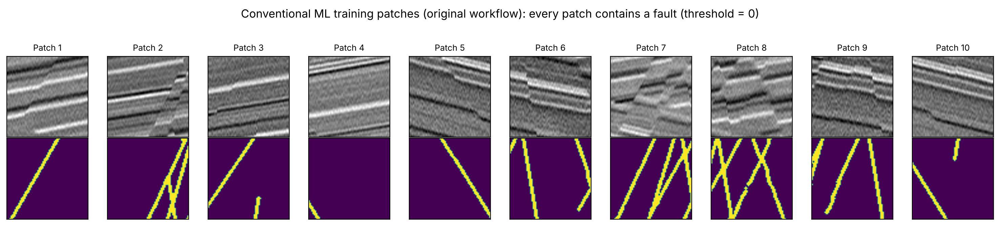

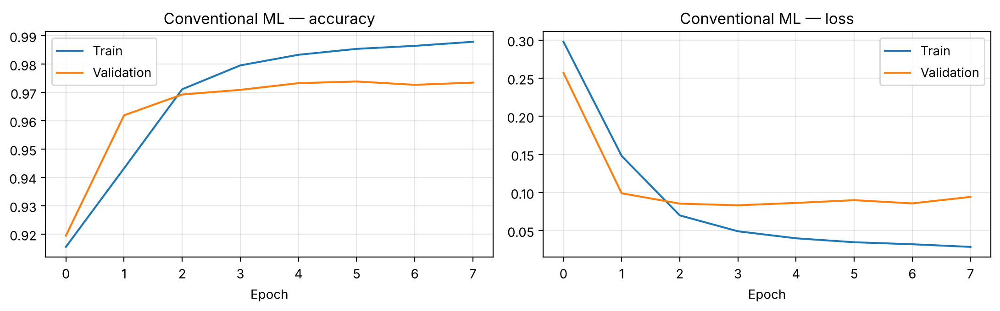

In [7]:
# ---------- original notebook functions (unchanged logic) ----------
def patchify(data, label, size, number, threshold, rng):
    t_max, x_max = label.shape
    X = np.zeros((number, size, size, 1), np.float32); Y = np.zeros((number, size, size, 1), np.float32)
    n = attempts = 0
    while n < number and attempts < number * 20:
        attempts += 1
        x = rng.integers(size // 2, x_max - size // 2); t = rng.integers(size // 2, t_max - size // 2)
        pl = label[t - size // 2: t + size // 2, x - size // 2: x + size // 2]
        if np.count_nonzero(pl) > threshold:
            X[n, :, :, 0] = data[t - size // 2: t + size // 2, x - size // 2: x + size // 2]; Y[n, :, :, 0] = pl; n += 1
    if n < number: print(f"WARNING: only {n}/{number} patches")
    return X[:n], Y[:n]

def UNet_original(input_size):
    def down(x, f):
        c = layers.Conv2D(f, 3, padding="same", activation="relu")(x); c = layers.Conv2D(f, 3, padding="same", activation="relu")(c)
        return c, layers.MaxPool2D(2)(c)
    def up(x, skip, f):
        x = layers.Concatenate()([layers.UpSampling2D(2)(x), skip])
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); return layers.Conv2D(f, 3, padding="same", activation="relu")(x)
    f = [16, 32, 64, 128, 256]
    inp = keras.Input((input_size, input_size, 1)); c1, p1 = down(inp, f[0]); c2, p2 = down(p1, f[1])
    c3, p3 = down(p2, f[2]); c4, p4 = down(p3, f[3])
    bn = layers.Conv2D(f[4], 3, padding="same", activation="relu")(p4); bn = layers.Conv2D(f[4], 3, padding="same", activation="relu")(bn)
    u = up(bn, c4, f[3]); u = up(u, c3, f[2]); u = up(u, c2, f[1]); u = up(u, c1, f[0])
    return keras.Model(inp, layers.Conv2D(1, 1, activation="sigmoid")(u), name="UNet_original")

def tile(data, wsize, dt, dx):
    t_max, x_max = data.shape
    ts = [min(t, t_max - wsize) for t in range(0, t_max, dt)]; xs = [min(x, x_max - wsize) for x in range(0, x_max, dx)]
    return np.stack([data[t:t + wsize, x:x + wsize] for t in ts for x in xs])[..., None], ts, xs

def merge(patches, t_max, x_max, wsize, ts, xs):
    out = np.zeros((t_max, x_max)); cnt = np.zeros((t_max, x_max)); n = 0
    for t in ts:
        for x in xs:
            out[t:t + wsize, x:x + wsize] += patches[n, :, :, 0]; cnt[t:t + wsize, x:x + wsize] += 1; n += 1
    return out / cnt

def conv_predict_section(model, sec):
    p, ts, xs = tile(sec, CONV_PATCH, CONV_DT, CONV_DT)
    return merge(model.predict(p, batch_size=256, verbose=0), sec.shape[0], sec.shape[1], CONV_PATCH, ts, xs).astype(np.float32)

def train_conventional(survey, tag):
    rng = np.random.default_rng(SEED + 11)
    per = CONV_N_TRAIN // len(survey["train"])
    parts = [patchify(survey["conv_section"](k), survey["labels"][k], CONV_PATCH, per, CONV_THRESHOLD_PIX, rng) for k in survey["train"]]
    Xc, Yc = np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts])
    vk = survey["val"][0]
    Xcv, Ycv = patchify(survey["conv_section"](vk), survey["labels"][vk], CONV_PATCH, CONV_N_VAL, CONV_THRESHOLD_PIX, rng)
    m = UNet_original(CONV_PATCH)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
          keras.callbacks.CSVLogger(os.path.join(RUN_DIR, f"history_conventional_{tag}.csv"))]
    h = m.fit(Xc, Yc, validation_data=(Xcv, Ycv), epochs=CONV_EPOCHS, batch_size=CONV_BATCH, callbacks=cb, verbose=2)
    m.save(os.path.join(RUN_DIR, f"conventional_{tag}.keras"))
    return m, pd.DataFrame(h.history), (Xc, Yc)

t0 = time.time()
if PRETRAINED_CONV_MODEL:
    conv_model = keras.models.load_model(PRETRAINED_CONV_MODEL)
    hf = os.path.join(os.path.dirname(os.path.abspath(PRETRAINED_CONV_MODEL)), "history_conventional_benchmark.csv")
    conv_hist = pd.read_csv(hf) if os.path.exists(hf) else None
    Xc, Yc = patchify(BENCH["conv_section"](train_idx[0]), BENCH["labels"][train_idx[0]], CONV_PATCH, 40, 0, np.random.default_rng(0))
else:
    conv_model, conv_hist, (Xc, Yc) = train_conventional(BENCH, "benchmark")
print(f"conventional training: {(time.time() - t0) / 60:.1f} min")

# original-notebook figures: training patches + accuracy / loss curves
fig, axs = plt.subplots(2, 10, figsize=(15, 3.2))
for m in range(10):
    axs[0, m].imshow(Xc[m, :, :, 0], interpolation="spline16", cmap=plt.cm.gray, aspect=1); axs[0, m].set_title(f"Patch {m + 1}", fontsize=9)
    axs[1, m].imshow(Yc[m, :, :, 0], interpolation="spline16", aspect=1, vmin=0, vmax=1)
    for a in axs[:, m]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Conventional ML training patches (original workflow): every patch contains a fault (threshold = 0)", y=1.03)
plt.tight_layout(); savefig("fig_conventional_training_patches.png"); plt.show()
if conv_hist is not None:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(conv_hist["accuracy"]); ax[0].plot(conv_hist["val_accuracy"]); ax[0].set_title("Conventional ML — accuracy")
    ax[1].plot(conv_hist["loss"]); ax[1].plot(conv_hist["val_loss"]); ax[1].set_title("Conventional ML — loss")
    for a in ax: a.legend(["Train", "Validation"]); a.set_xlabel("Epoch"); a.grid(alpha=.3)
    plt.tight_layout(); savefig("fig_conventional_curves.png"); plt.show()

## 7. SciML network: training on physics-based data (no labels from the survey)
U-Net with batch-norm and Monte-Carlo dropout; loss = class-weighted BCE + soft Dice, masked where labels are unknown (used for 3D sparse-slice fine-tuning). The decision threshold is chosen on the **synthetic** validation set, so the label-free SciML result uses no survey labels at all.

loaded /home/claude/f3/models_final/sciml_model.keras
SciML training: 0.0 min


label-free SciML threshold (from synthetic validation): 0.738


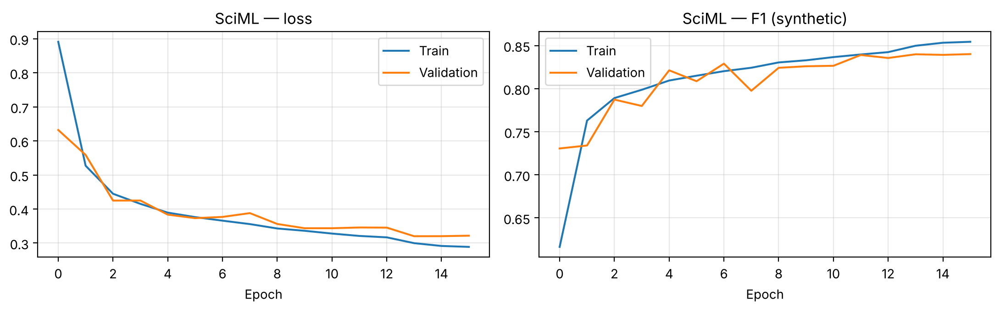

In [8]:
@keras.saving.register_keras_serializable(package="sciml")
class MCDropout(layers.Layer):
    # spatial dropout that can stay active at inference (Monte-Carlo uncertainty) via the flag `mc_on`
    def __init__(self, rate, **kw):
        super().__init__(**kw); self.rate = float(rate); self.seed_gen = keras.random.SeedGenerator(SEED)
    def build(self, input_shape):
        self.mc_on = self.add_weight(name="mc_on", shape=(), initializer="zeros", trainable=False)
    def call(self, x, training=None):
        if self.rate <= 0: return x
        shp = ops.shape(x); ns = (shp[0],) + (1,) * (len(x.shape) - 2) + (shp[-1],)
        keep = ops.cast(keras.random.uniform(ns, seed=self.seed_gen) >= self.rate, x.dtype)
        a = 1.0 if training else self.mc_on
        return a * x * keep / (1.0 - self.rate) + (1.0 - a) * x
    def get_config(self): return {**super().get_config(), "rate": self.rate}

def set_mc_dropout(model, on):
    for l in model.layers:
        if isinstance(l, MCDropout): l.mc_on.assign(1.0 if on else 0.0)

def build_unet(nd, base=16, depth=4, dropout=0.1):
    Conv = layers.Conv2D if nd == 2 else layers.Conv3D; Pool = layers.MaxPooling2D if nd == 2 else layers.MaxPooling3D
    Up = layers.Conv2DTranspose if nd == 2 else layers.Conv3DTranspose
    def block(x, f):
        for _ in range(2):
            x = Conv(f, 3, padding="same", use_bias=False, kernel_initializer="he_normal")(x)
            x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        return x
    inp = keras.Input((None,) * nd + (1,)); x, skips = inp, []
    for d in range(depth):
        x = block(x, base * 2 ** d); skips.append(x); x = Pool(2)(x)
    x = MCDropout(dropout, name="mc_bottleneck")(block(x, base * 2 ** depth))
    for d in reversed(range(depth)):
        x = Up(base * 2 ** d, 2, strides=2, padding="same")(x)
        x = block(layers.Concatenate()([x, skips[d]]), base * 2 ** d)
        if d >= depth - 2: x = MCDropout(dropout, name=f"mc_dec{d}")(x)
    return keras.Model(inp, Conv(1, 1, activation="sigmoid", dtype="float32")(x), name=f"SciML_UNet{nd}D")

def pos_weight(*Ys, cap=30.0):
    pos = sum(float((Y == 1).sum()) for Y in Ys); known = sum(float((Y >= 0).sum()) for Y in Ys)
    pi = max(pos / max(known, 1), 1e-4); return float(np.clip(np.sqrt((1 - pi) / pi), 1, cap))

def masked_bce_dice(pw, dice_weight=DICE_WEIGHT):
    def loss(y_true, y_pred):
        m = tf.cast(y_true >= 0, tf.float32); y = tf.clip_by_value(y_true, 0, 1); p = tf.clip_by_value(y_pred, 1e-6, 1 - 1e-6)
        bce = tf.reduce_sum(-(pw * y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p)) * m) / (tf.reduce_sum(m) + 1e-6)
        dice = 1 - (2 * tf.reduce_sum(m * p * y) + 1) / (tf.reduce_sum(m * (p + y)) + 1)
        return bce + dice_weight * dice
    return loss

def masked_f1(y_true, y_pred):
    m = tf.cast(y_true >= 0, tf.float32); y = tf.clip_by_value(y_true, 0, 1); pb = tf.cast(y_pred > 0.5, tf.float32)
    tp = tf.reduce_sum(pb * y * m); fp = tf.reduce_sum(pb * (1 - y) * m); fn = tf.reduce_sum((1 - pb) * y * m)
    return 2 * tp / (2 * tp + fp + fn + 1e-6)

def augment(x, y):
    for ax in range(1, NDIM):
        flip = tf.random.uniform(()) < 0.5
        x = tf.cond(flip, lambda: tf.reverse(x, [ax]), lambda: x); y = tf.cond(flip, lambda: tf.reverse(y, [ax]), lambda: y)
    x = x * tf.where(tf.random.uniform(()) < 0.5, -1.0, 1.0) + tf.random.normal(tf.shape(x), stddev=0.05)
    return x, y

def make_ds(X, Y, train=False):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if train: ds = ds.shuffle(min(len(X), 4096), seed=SEED)
    ds = ds.map(lambda x, y: (x, tf.cast(y, tf.float32)), num_parallel_calls=tf.data.AUTOTUNE)
    if train: ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def fit_sciml(m, X, Y, Xv, Yv, epochs, lr, tag):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=masked_bce_dice(pos_weight(Y)), metrics=[masked_f1])
    cb = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
          keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
          keras.callbacks.CSVLogger(os.path.join(RUN_DIR, f"history_{tag}.csv"))]
    return pd.DataFrame(m.fit(make_ds(X, Y, True), validation_data=make_ds(Xv, Yv), epochs=epochs, callbacks=cb, verbose=2).history)

def best_threshold(prob, truth):
    pr, rc, th = precision_recall_curve(truth.ravel().astype(bool), prob.ravel())
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    return float(th[np.argmax(f1[:-1])]) if len(th) else 0.5

t0 = time.time()
if PRETRAINED_MODEL:
    sciml = keras.models.load_model(PRETRAINED_MODEL, compile=False)
    hf = os.path.join(os.path.dirname(os.path.abspath(PRETRAINED_MODEL)), "history_sciml_synthetic.csv")
    sciml_hist = pd.read_csv(hf) if os.path.exists(hf) else None
    print("loaded", PRETRAINED_MODEL)
else:
    sciml = build_unet(NDIM, BASE_FILTERS, DEPTH, DROPOUT)
    print(sciml.name, f"{sciml.count_params():,} parameters")
    sciml_hist = fit_sciml(sciml, Xs_tr, Ys_tr, Xs_va, Ys_va, EPOCHS, LR, "sciml_synthetic")
sciml.save(os.path.join(RUN_DIR, "sciml_model.keras"))
print(f"SciML training: {(time.time() - t0) / 60:.1f} min")
SYNTH_THR = best_threshold(sciml.predict(Xs_va, batch_size=BATCH, verbose=0), Ys_va == 1)
print(f"label-free SciML threshold (from synthetic validation): {SYNTH_THR:.3f}")
if sciml_hist is not None:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(sciml_hist["loss"]); ax[0].plot(sciml_hist["val_loss"]); ax[0].set_title("SciML — loss")
    ax[1].plot(sciml_hist["masked_f1"]); ax[1].plot(sciml_hist["val_masked_f1"]); ax[1].set_title("SciML — F1 (synthetic)")
    for a in ax: a.legend(["Train", "Validation"]); a.set_xlabel("Epoch"); a.grid(alpha=.3)
    plt.tight_layout(); savefig("fig_sciml_curves.png"); plt.show()

In [9]:
# ---------- SciML + fine-tune on the SAME labelled inlines the conventional model used ----------
def labelled_patches(survey, idxs, n, seed):
    # 2D: patches from labelled sections; 3D: sparse-slice supervision (only the labelled inline is known, rest = -1)
    rng = np.random.default_rng(seed); vol = survey["vol"]; nt, nil, nxl = vol.shape
    X = np.zeros((n,) + (PATCH,) * NDIM + (1,), np.float32); Y = -np.ones((n,) + (PATCH,) * NDIM + (1,), np.int8)
    for i in range(n):
        k = idxs[i % len(idxs)]; lab = survey["labels"][k]; pos = np.argwhere(lab > 0)
        ct, cx = pos[rng.integers(len(pos))] if len(pos) and rng.random() < POS_FRACTION else (rng.integers(nt), rng.integers(nxl))
        t0 = int(np.clip(ct - PATCH // 2 + rng.integers(-PATCH // 4, PATCH // 4 + 1), 0, nt - PATCH))
        x0 = int(np.clip(cx - PATCH // 2 + rng.integers(-PATCH // 4, PATCH // 4 + 1), 0, nxl - PATCH))
        y2 = lab[t0:t0 + PATCH, x0:x0 + PATCH].astype(np.int8)
        v = survey["valid"](k)
        if v is not None: y2 = np.where(v[t0:t0 + PATCH, x0:x0 + PATCH], y2, -1).astype(np.int8)
        if NDIM == 2:
            X[i, ..., 0] = vol[t0:t0 + PATCH, k, x0:x0 + PATCH]; Y[i, ..., 0] = y2
        else:
            i0 = int(np.clip(k - rng.integers(0, PATCH), 0, nil - PATCH))
            X[i, ..., 0] = vol[t0:t0 + PATCH, i0:i0 + PATCH, x0:x0 + PATCH]; Y[i, :, k - i0, :, 0] = y2
    return X, Y

def finetune_sciml(base, survey, tag):
    tmp = os.path.join(RUN_DIR, "_tmp_base.keras"); base.save(tmp)
    m = keras.models.load_model(tmp, compile=False); os.remove(tmp)
    Xf, Yf = labelled_patches(survey, survey["train"], N_FT_PATCHES, SEED + 21)
    Xfv, Yfv = labelled_patches(survey, survey["val"], max(32, N_FT_PATCHES // 5), SEED + 22)
    fit_sciml(m, Xf, Yf, Xfv, Yfv, FINETUNE_EPOCHS, FINETUNE_LR, f"sciml_finetune_{tag}")
    m.save(os.path.join(RUN_DIR, f"sciml_finetuned_{tag}.keras"))
    return m

sciml_ft = None
if FINETUNE and PRETRAINED_FT_MODEL:
    sciml_ft = keras.models.load_model(PRETRAINED_FT_MODEL, compile=False); print("loaded", PRETRAINED_FT_MODEL)
elif FINETUNE:
    t0 = time.time(); sciml_ft = finetune_sciml(sciml, BENCH, "benchmark")
    print(f"SciML fine-tuning: {(time.time() - t0) / 60:.1f} min")

loaded /home/claude/f3/models_final/sciml_finetuned_benchmark.keras


## 8. Predictions on the benchmark survey
Every method predicts the validation inline (for threshold tuning) and all held-out test inlines.

In [10]:
def _starts(n, p, step):
    s = list(range(0, max(n - p, 0) + 1, step))
    if s[-1] != max(n - p, 0): s.append(max(n - p, 0))
    return s

def sliding_window_predict(model, x, patch=PATCH, overlap=OVERLAP, batch=BATCH):
    # x: (*spatial) -> probability (*spatial), Gaussian-weighted blending
    sp = x.shape; nd = len(sp)
    f = np.pad(x, [(0, max(0, patch - s)) for s in sp], mode="symmetric"); S = f.shape
    step = max(1, int(patch * (1 - overlap)))
    g1 = np.exp(-0.5 * ((np.arange(patch) - (patch - 1) / 2) / (patch / 4)) ** 2); w = g1
    for _ in range(nd - 1): w = np.multiply.outer(w, g1)
    w = np.maximum(w, 1e-3).astype(np.float32)
    out = np.zeros(S, np.float32); ws = np.zeros(S, np.float32)
    corners = list(itertools.product(*[_starts(n, patch, step) for n in S]))
    for b in range(0, len(corners), batch):
        cs = corners[b:b + batch]
        xb = np.stack([f[tuple(slice(c, c + patch) for c in cc)] for cc in cs])[..., None]
        pb = np.asarray(model.predict_on_batch(xb))[..., 0]
        for cc, p in zip(cs, pb):
            sl = tuple(slice(c, c + patch) for c in cc); out[sl] += p * w; ws[sl] += w
    return (out / ws)[tuple(slice(0, s) for s in sp)]

def predict_with_uncertainty(model, x, n_mc=MC_SAMPLES):
    set_mc_dropout(model, False); det = sliding_window_predict(model, x)
    if n_mc and n_mc > 1:
        set_mc_dropout(model, True); s = np.stack([sliding_window_predict(model, x) for _ in range(n_mc)]); set_mc_dropout(model, False)
        return s.mean(0), s.std(0)
    return det, np.zeros_like(det)

def sciml_predict_inlines(model, vol, idxs):
    set_mc_dropout(model, False)
    if NDIM == 2:
        return {k: sliding_window_predict(model, vol[:, k, :]) for k in idxs}
    if vol.size <= 40e6:                                   # small survey: predict the whole cube once
        cube = sliding_window_predict(model, vol); return {k: cube[:, k, :] for k in idxs}
    out = {}
    for k in idxs:                                         # large survey: slab around each inline
        i0 = int(np.clip(k - PATCH // 2, 0, max(vol.shape[1] - PATCH, 0)))
        out[k] = sliding_window_predict(model, vol[:, i0:i0 + PATCH, :])[:, k - i0, :]
    return out

def gst_discontinuity(x, sigma_g=1.0, sigma_t=2.5):
    g = [ndi.gaussian_filter(x, sigma_g, order=o) for o in ([1, 0], [0, 1])]
    T = np.stack([np.stack([ndi.gaussian_filter(a * b, sigma_t) for b in g], -1) for a in g], -2)
    lam = np.linalg.eigvalsh(T)[..., ::-1]
    return np.clip(1 - (lam[..., 0] - lam[..., 1]) / (lam[..., 0] + lam[..., 1] + 1e-9), 0, 1).astype(np.float32)

def predict_all_methods(survey):
    idxs = survey["val"] + survey["test"]
    P = {"GST attribute (no ML)": {k: gst_discontinuity(survey["vol"][:, k, :]) for k in idxs},
         "Conventional ML": {k: conv_predict_section(conv_model, survey["conv_section"](k)) for k in idxs},
         "SciML (no labels)": sciml_predict_inlines(sciml, survey["vol"], idxs)}
    if sciml_ft is not None:
        P["SciML + fine-tune"] = sciml_predict_inlines(sciml_ft, survey["vol"], idxs)
    return P

t0 = time.time()
PRED = predict_all_methods(BENCH)
print(f"predictions for {len(PRED)} methods on {len(BENCH['val'] + BENCH['test'])} inlines: {time.time() - t0:.0f}s")

predictions for 4 methods on 19 inlines: 35s


## 9. Quantitative comparison (held-out test inlines)
* **Thresholds** — Conventional ML is scored both *as published* (0.5) and with its threshold tuned on the validation inline (its best case). SciML (no labels) uses the threshold from synthetic validation; SciML + fine-tune and the attribute use the validation inline.
* **Metrics** (pixels pooled over all test inlines): accuracy, precision, recall, F1, IoU, Matthews correlation (MCC), average precision (AP, threshold-free) and tolerance-F1 (a hit within 2 pixels counts).
* **Accuracy is reported only to show why it is misleading**: a model that never predicts a fault already scores ≈ 98 %.
* **Uncertainty** — 95 % bootstrap confidence intervals by resampling test inlines; the paired bootstrap of ΔF1 = F1(SciML) − F1(Conventional) gives the probability that SciML is better.

In [11]:
def cm_counts(prob, truth, thr, valid=None):
    p = prob >= thr; t = truth > 0
    if valid is not None: p, t = p[valid], t[valid]
    return np.array([[np.sum(~p & ~t), np.sum(p & ~t)], [np.sum(~p & t), np.sum(p & t)]], np.int64)

def scores(cm):
    (tn, fp), (fn, tp) = cm.astype(float)
    pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
    mcc = (tp * tn - fp * fn) / max(np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)), 1)
    return dict(Accuracy=(tp + tn) / cm.sum(), Precision=pr, Recall=rc, F1=2 * tp / max(2 * tp + fp + fn, 1),
                IoU=tp / max(tp + fp + fn, 1), MCC=mcc)

def tolerance_f1(pb, t, valid=None, r=2):
    v = np.ones_like(t, bool) if valid is None else valid
    td = ndi.binary_dilation(t, iterations=r); pdl = ndi.binary_dilation(pb, iterations=r)
    p = (pb & td & v).sum() / max((pb & v).sum(), 1); rc = (t & pdl & v).sum() / max((t & v).sum(), 1)
    return 2 * p * rc / max(p + rc, 1e-9)

def evaluate_survey(survey, P):
    vk = survey["val"][0]; tv = survey["labels"][vk] > 0; vv = survey["valid"](vk)
    sel = (lambda a: a if vv is None else a[vv])
    rows = {"Trivial: all 'No fault'": ({k: np.zeros_like(P["Conventional ML"][k]) for k in survey["test"]}, 0.5)}
    rows["GST attribute (no ML)"] = (P["GST attribute (no ML)"], best_threshold(sel(P["GST attribute (no ML)"][vk]), sel(tv)))
    rows["Conventional ML (as published, thr 0.5)"] = (P["Conventional ML"], 0.5)
    rows["Conventional ML (tuned thr)"] = (P["Conventional ML"], best_threshold(sel(P["Conventional ML"][vk]), sel(tv)))
    rows["SciML (no labels)"] = (P["SciML (no labels)"], SYNTH_THR)
    if "SciML + fine-tune" in P:
        rows["SciML + fine-tune"] = (P["SciML + fine-tune"], best_threshold(sel(P["SciML + fine-tune"][vk]), sel(tv)))
    table, per_inline, cms = [], {}, {}
    rng = np.random.default_rng(0)
    for name, (pp, thr) in rows.items():
        per = np.stack([cm_counts(pp[k], survey["labels"][k], thr, survey["valid"](k)) for k in survey["test"]])
        cm = per.sum(0); s = scores(cm)
        tp_all = np.concatenate([(survey["labels"][k] > 0)[survey["valid"](k)] if survey["valid"](k) is not None else (survey["labels"][k] > 0).ravel() for k in survey["test"]])
        pp_all = np.concatenate([pp[k][survey["valid"](k)] if survey["valid"](k) is not None else pp[k].ravel() for k in survey["test"]])
        sub = rng.choice(len(tp_all), min(len(tp_all), 3_000_000), replace=False)
        s["AP"] = average_precision_score(tp_all[sub], pp_all[sub]) if pp_all.max() > pp_all.min() else tp_all.mean()
        s["tol-F1 (2 px)"] = np.mean([tolerance_f1(pp[k] >= thr, survey["labels"][k] > 0, survey["valid"](k)) for k in survey["test"]])
        boot = [scores(per[rng.integers(0, len(per), len(per))].sum(0))["F1"] for _ in range(1000)]
        s["F1 95% CI"] = f"{np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}"
        s["threshold"] = thr
        table.append(dict(Method=name, **s)); per_inline[name] = per; cms[name] = cm
    return pd.DataFrame(table).set_index("Method"), per_inline, cms

RES, PER_INLINE, CMS = evaluate_survey(BENCH, PRED)
RES.to_csv(os.path.join(RUN_DIR, "metrics_benchmark.csv"))
pd.options.display.float_format = "{:.3f}".format
RES

,Accuracy,Precision,Recall,F1,IoU,MCC,AP,tol-F1 (2 px),F1 95% CI,threshold
Method,,,,,,,,,,
Trivial: all 'No fault',0.938,0.000,0.000,0.000,0.000,0.000,0.062,0.000,0.000–0.000,0.500
GST attribute (no ML),0.765,0.153,0.614,0.244,0.139,0.217,0.136,0.420,0.241–0.248,0.221
"Conventional ML (as published, thr 0.5)",0.981,0.832,0.869,0.850,0.740,0.840,0.924,0.970,0.846–0.855,0.500
Conventional ML (tuned thr),0.981,0.828,0.873,0.850,0.739,0.840,0.924,0.970,0.846–0.854,0.488
SciML (no labels),0.979,0.871,0.780,0.823,0.699,0.814,0.904,0.958,0.817–0.829,0.738
SciML + fine-tune,0.985,0.878,0.884,0.881,0.787,0.873,0.952,0.985,0.877–0.885,0.635


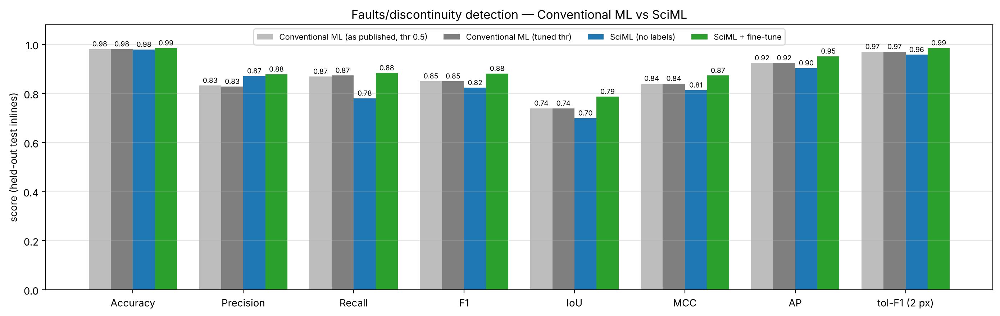

Comparison,SciML (no labels) vs Conventional ML (tuned thr),SciML + fine-tune vs Conventional ML (tuned thr)
Precision,0.871 vs 0.828 (+5%),0.878 vs 0.828 (+6%)
Recall,0.780 vs 0.873 (-11%),0.884 vs 0.873 (+1%)
F1,0.823 vs 0.850 (-3%),0.881 vs 0.850 (+4%)
IoU,0.699 vs 0.739 (-5%),0.787 vs 0.739 (+6%)
MCC,0.814 vs 0.840 (-3%),0.873 vs 0.840 (+4%)
AP,0.904 vs 0.924 (-2%),0.952 vs 0.924 (+3%)
tol-F1 (2 px),0.958 vs 0.970 (-1%),0.985 vs 0.970 (+2%)
False alarms (FP),-36%,-32%
Missed faults (FN),+73%,-8%
ΔF1 95% CI,-0.035 to -0.019,+0.027 to +0.035


In [12]:
# ---------- improvement of SciML over Conventional ML ----------
REF = "Conventional ML (tuned thr)"
rows = []
for name in [n for n in RES.index if n.startswith("SciML")]:
    r = {"Comparison": f"{name}  vs  {REF}"}
    for mtr in ["Precision", "Recall", "F1", "IoU", "MCC", "AP", "tol-F1 (2 px)"]:
        a, b = RES.loc[REF, mtr], RES.loc[name, mtr]
        r[f"{mtr}"] = f"{b:.3f} vs {a:.3f} ({(b - a) / max(a, 1e-9) * 100:+.0f}%)"
    (tn0, fp0), (fn0, tp0) = CMS[REF]; (tn1, fp1), (fn1, tp1) = CMS[name]
    r["False alarms (FP)"] = f"{(fp1 - fp0) / max(fp0, 1) * 100:+.0f}%"
    r["Missed faults (FN)"] = f"{(fn1 - fn0) / max(fn0, 1) * 100:+.0f}%"
    d = []
    rng = np.random.default_rng(1); P0, P1 = PER_INLINE[REF], PER_INLINE[name]
    for _ in range(2000):
        ii = rng.integers(0, len(P0), len(P0)); d.append(scores(P1[ii].sum(0))["F1"] - scores(P0[ii].sum(0))["F1"])
    r["ΔF1 95% CI"] = f"{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}"
    r["P(SciML better)"] = f"{np.mean(np.array(d) > 0):.3f}"
    rows.append(r)
IMPROVE = pd.DataFrame(rows).set_index("Comparison").T
IMPROVE.to_csv(os.path.join(RUN_DIR, "improvement_benchmark.csv"))

# bar chart of the main metrics
show = ["Conventional ML (as published, thr 0.5)", "Conventional ML (tuned thr)", "SciML (no labels)"] + \
       (["SciML + fine-tune"] if "SciML + fine-tune" in RES.index else [])
cols = {show[0]: "#bdbdbd", show[1]: C_CONV, "SciML (no labels)": C_SCIML, "SciML + fine-tune": C_FT}
mets = ["Accuracy", "Precision", "Recall", "F1", "IoU", "MCC", "AP", "tol-F1 (2 px)"]
fig, ax = plt.subplots(figsize=(14, 4.5)); w = 0.8 / len(show)
for i, n in enumerate(show):
    v = RES.loc[n, mets].astype(float).values
    b = ax.bar(np.arange(len(mets)) + (i - (len(show) - 1) / 2) * w, v, w, label=n, color=cols[n])
    ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(range(len(mets)), mets); ax.set_ylim(0, 1.08); ax.set_ylabel("score (held-out test inlines)")
ax.set_title(f"{CLASS_NAME} detection — Conventional ML vs SciML"); ax.legend(fontsize=8, ncol=4, loc="upper center"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); savefig("fig_metrics_comparison.png"); plt.show()
IMPROVE

## 10. Confusion matrices
Same style as the original notebook (row-normalised; counts in brackets), pooled over all held-out test inlines. The last panel is the **difference SciML − Conventional ML**: green = SciML better (more faults found, fewer false alarms), red = worse.

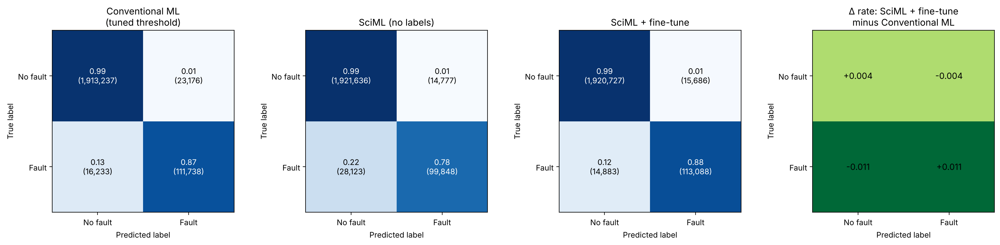

SciML + fine-tune vs Conventional ML on 18 test inlines: fault detection rate 87.3% -> 88.4%;  false alarms 23,176 -> 15,686 px (-32%)


In [13]:
def plot_cm(ax, cm, title, cmap=plt.cm.Blues):
    cmn = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(cmn, interpolation="nearest", cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]:,})", ha="center", va="center", fontsize=10,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No fault", "Fault"], yticklabels=["No fault", "Fault"],
           title=title, ylabel="True label", xlabel="Predicted label")
    return im

panels = [n for n in ["Conventional ML (tuned thr)", "SciML (no labels)", "SciML + fine-tune"] if n in CMS]
fig, ax = plt.subplots(1, len(panels) + 1, figsize=(4.6 * (len(panels) + 1), 4.3))
for a, n in zip(ax, panels):
    plot_cm(a, CMS[n], n.replace(" (tuned thr)", "\n(tuned threshold)"))
best = panels[-1]
d = CMS[best] / CMS[best].sum(1, keepdims=True) - CMS[REF] / CMS[REF].sum(1, keepdims=True)
good = np.array([[1, -1], [-1, 1]]) * np.sign(d)    # TN up, FP down, FN down, TP up = good (green)
im = ax[-1].imshow(good * np.abs(d), cmap="RdYlGn", vmin=-max(np.abs(d).max(), 1e-3), vmax=max(np.abs(d).max(), 1e-3))
for i in range(2):
    for j in range(2): ax[-1].text(j, i, f"{d[i, j]:+.3f}", ha="center", va="center", fontsize=11)
ax[-1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No fault", "Fault"], yticklabels=["No fault", "Fault"],
           title=f"Δ rate: {best}\nminus Conventional ML", ylabel="True label", xlabel="Predicted label")
plt.tight_layout(); savefig("fig_confusion_matrices.png"); plt.show()
(tn0, fp0), (fn0, tp0) = CMS[REF]; (tn1, fp1), (fn1, tp1) = CMS[best]
print(f"{best} vs Conventional ML on {len(BENCH['test'])} test inlines: fault detection rate "
      f"{tp0 / (tp0 + fn0):.1%} -> {tp1 / (tp1 + fn1):.1%};  false alarms {fp0:,} -> {fp1:,} px ({(fp1 - fp0) / max(fp0, 1):+.0%})")

## 11. Where SciML improves the prediction
* **Error maps** on a held-out inline: green = correctly detected fault (TP), red = false alarm (FP), blue = missed fault (FN).
* **Precision–recall curves** (threshold-free).
* **Per-inline F1**: every point is one test inline; points above the diagonal are inlines where SciML beats Conventional ML.

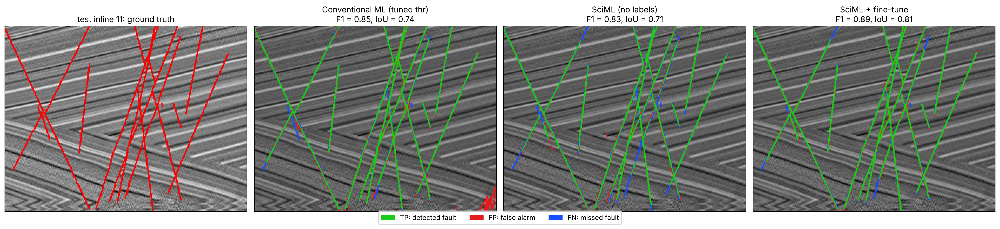

/tmp/ipykernel_2688/4231085034.py:39: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); savefig("fig_pr_and_per_inline.png"); plt.show()


/tmp/ipykernel_2688/631495970.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(os.path.join(RUN_DIR, name), dpi=130, bbox_inches="tight")


/usr/local/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


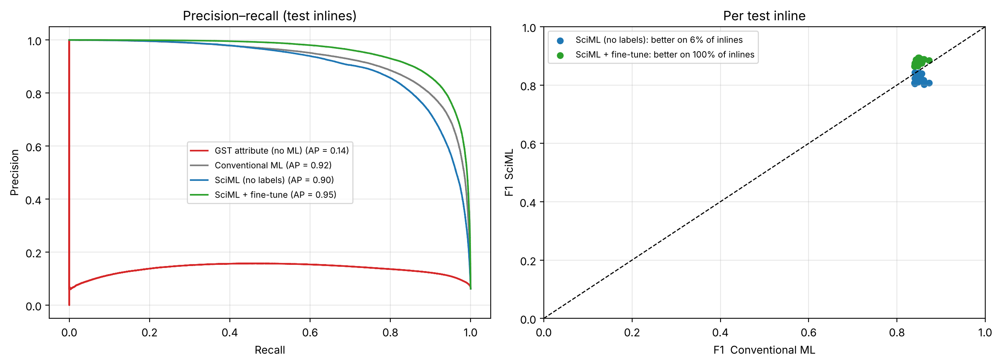

In [14]:
def error_rgb(sec, prob, truth, thr):
    g = (sec - sec.min()) / (np.ptp(sec) + 1e-9); rgb = np.stack([g] * 3, -1) * 0.75
    p = prob >= thr; t = truth > 0
    rgb[p & t] = [0.1, 0.8, 0.1]; rgb[p & ~t] = [0.9, 0.1, 0.1]; rgb[~p & t] = [0.1, 0.3, 1.0]
    return rgb

f1_conv = np.array([scores(c)["F1"] for c in PER_INLINE[REF]])
k_show = BENCH["test"][int(np.argsort(f1_conv)[len(f1_conv) // 2])]      # a typical (median) test inline
meths = [(REF, "Conventional ML"), ("SciML (no labels)", "SciML (no labels)")] + \
        ([("SciML + fine-tune", "SciML + fine-tune")] if "SciML + fine-tune" in RES.index else [])
fig, ax = plt.subplots(1, len(meths) + 1, figsize=(5.2 * (len(meths) + 1), 4.6))
sec = BENCH_VOL[:, k_show]; tr = BENCH["labels"][k_show]
ax[0].imshow(sec, cmap="gray", aspect="auto"); ax[0].imshow(np.ma.masked_equal(tr, 0), cmap="autumn", aspect="auto", interpolation="none")
ax[0].set_title(f"test inline {k_show}: ground truth")
for a, (row, pk) in zip(ax[1:], meths):
    thr = RES.loc[row, "threshold"]; a.imshow(error_rgb(sec, PRED[pk][k_show], tr, thr), aspect="auto")
    s = scores(cm_counts(PRED[pk][k_show], tr, thr)); a.set_title(f"{row}\nF1 = {s['F1']:.2f}, IoU = {s['IoU']:.2f}")
for a in ax: a.set_xticks([]); a.set_yticks([])
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=l) for c, l in [((0.1, .8, .1), "TP: detected fault"), ((.9, .1, .1), "FP: false alarm"), ((.1, .3, 1), "FN: missed fault")]],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); savefig("fig_error_maps.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
truth_all = np.concatenate([(BENCH["labels"][k] > 0).ravel() for k in BENCH["test"]])
for pk, c in [("GST attribute (no ML)", C_BASE), ("Conventional ML", C_CONV), ("SciML (no labels)", C_SCIML), ("SciML + fine-tune", C_FT)]:
    if pk not in PRED: continue
    pa = np.concatenate([PRED[pk][k].ravel() for k in BENCH["test"]])
    sub = np.random.default_rng(0).choice(len(pa), min(len(pa), 2_000_000), replace=False)
    pr, rc, _ = precision_recall_curve(truth_all[sub], pa[sub])
    ax[0].plot(rc, pr, color=c, label=f"{pk} (AP = {average_precision_score(truth_all[sub], pa[sub]):.2f})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision–recall (test inlines)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
for row, c in [("SciML (no labels)", C_SCIML), ("SciML + fine-tune", C_FT)]:
    if row in PER_INLINE:
        f1s = np.array([scores(cm)["F1"] for cm in PER_INLINE[row]])
        ax[1].scatter(f1_conv, f1s, color=c, label=f"{row}: better on {np.mean(f1s > f1_conv):.0%} of inlines", s=28)
lim = [0, 1]; ax[1].plot(lim, lim, "k--", lw=1); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel("F1  Conventional ML"); ax[1].set_ylabel("F1  SciML"); ax[1].set_title("Per test inline"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("fig_pr_and_per_inline.png"); plt.show()

## 12. Application to F3: Conventional ML vs SciML (one figure)
Both models are applied to the real F3 inline. Without an F3 interpretation we use **label-free, physically based quality measures**. The key one follows from geology: *a fault cuts reflectors at a high angle*, so detections that run **parallel to the reflectors** (angle < 20°, measured with the gradient structure tensor of the seismic and of the prediction) are almost certainly false alarms on strong horizons. We also report flagged area, number of segments, mean segment length and the share of isolated specks (< 20 px). If `LABEL_DIR` with F3 masks is given, both methods are also scored on the held-out F3 inline (`TEST_INLINES`) with the conventional model retrained on the F3 labels, exactly as in the paper.

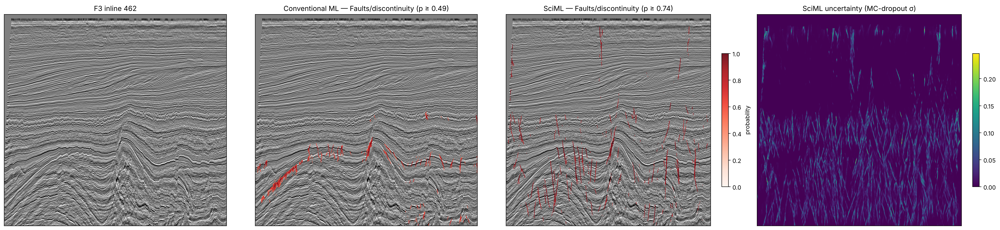

,flagged area (%),fault segments,mean segment length (px),isolated specks (% of flagged),"detections parallel to reflectors (<20°, %)",median angle to reflectors (°)
Conventional ML,1.151,112.000,20.241,5.494,19.484,46.210
SciML,2.059,284.000,18.042,6.717,2.710,67.296


In [15]:
from skimage.morphology import skeletonize

def layer_normals(img, sg=1.0, st=3.0):
    # unit normal of the dominant local orientation (gradient structure tensor)
    gx = ndi.gaussian_filter(img, sg, order=[1, 0]); gy = ndi.gaussian_filter(img, sg, order=[0, 1])
    a = ndi.gaussian_filter(gx * gx, st); b = ndi.gaussian_filter(gx * gy, st); c = ndi.gaussian_filter(gy * gy, st)
    th = 0.5 * np.arctan2(2 * b, a - c); return np.cos(th), np.sin(th)

def angle_to_reflectors(prob, sec):
    # angle (deg) between the orientation of the detection and the local reflector orientation
    s0, s1 = layer_normals(sec); d0, d1 = layer_normals(prob.astype(np.float32), 1.0, 2.0)
    return np.degrees(np.arccos(np.clip(np.abs(s0 * d0 + s1 * d1), 0, 1)))

def segment_stats(binary, valid, prob, sec):
    b = binary & valid; lab, n = ndi.label(b, structure=np.ones((3, 3)))
    ang = angle_to_reflectors(prob, sec)[b] if b.any() else np.array([0.0])
    sizes = np.bincount(lab.ravel())[1:] if n else np.array([0])
    sk = skeletonize(b); sk_lab, _ = ndi.label(sk, structure=np.ones((3, 3)))
    lengths = np.bincount(sk_lab.ravel())[1:] if sk_lab.max() else np.array([0])
    return {"flagged area (%)": 100 * b.sum() / max(valid.sum(), 1), "fault segments": int(n),
            "mean segment length (px)": float(lengths[lengths >= 1].mean()) if lengths.size else 0.0,
            "isolated specks (% of flagged)": 100 * sizes[sizes < 20].sum() / max(sizes.sum(), 1),
            "detections parallel to reflectors (<20°, %)": 100 * np.mean(ang < 20),
            "median angle to reflectors (°)": float(np.median(ang))}

k3 = int(np.clip(il_to_index(PREDICT_INLINE), 0, NIL - 1)); il_name = GEOM["il_vals"][k3]
valid3 = f3_valid_section(k3); sec3 = VOL[:, k3, :]
p_conv3 = conv_predict_section(conv_model, f3_conv_section(k3)) * valid3
if NDIM == 2:
    p_sci3, s_sci3 = predict_with_uncertainty(sciml, sec3)
else:
    i0 = int(np.clip(k3 - PATCH // 2, 0, max(NIL - PATCH, 0)))
    pm, ps = predict_with_uncertainty(sciml, VOL[:, i0:i0 + PATCH, :], n_mc=min(MC_SAMPLES, 5)); p_sci3, s_sci3 = pm[:, k3 - i0], ps[:, k3 - i0]
p_sci3, s_sci3 = p_sci3 * valid3, s_sci3 * valid3
thr_conv, thr_sci = RES.loc[REF, "threshold"], SYNTH_THR
np.save(os.path.join(RUN_DIR, f"f3_inline_{il_name}_sciml_prob.npy"), p_sci3)

fig, ax = plt.subplots(1, 4, figsize=(24, 5.6))
ax[0].imshow(sec3, cmap="gray", aspect="auto", vmin=-3, vmax=3); ax[0].set_title(f"F3 inline {il_name}")
ax[1].imshow(sec3, cmap="gray", aspect="auto", vmin=-3, vmax=3)
ax[1].imshow(np.ma.masked_less(p_conv3, thr_conv), cmap="Reds", vmin=0, vmax=1, aspect="auto", alpha=0.9)
ax[1].set_title(f"Conventional ML — {CLASS_NAME} (p ≥ {thr_conv:.2f})")
ax[2].imshow(sec3, cmap="gray", aspect="auto", vmin=-3, vmax=3)
im = ax[2].imshow(np.ma.masked_less(p_sci3, thr_sci), cmap="Reds", vmin=0, vmax=1, aspect="auto", alpha=0.9)
ax[2].set_title(f"SciML — {CLASS_NAME} (p ≥ {thr_sci:.2f})"); plt.colorbar(im, ax=ax[2], fraction=0.03, label="probability")
im = ax[3].imshow(s_sci3, cmap="viridis", aspect="auto"); ax[3].set_title("SciML uncertainty (MC-dropout σ)")
plt.colorbar(im, ax=ax[3], fraction=0.03)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig(f"fig_F3_inline_{il_name}_conventional_vs_sciml.png"); plt.show()

F3_STATS = pd.DataFrame({"Conventional ML": segment_stats(p_conv3 >= thr_conv, valid3, p_conv3, sec3),
                         "SciML": segment_stats(p_sci3 >= thr_sci, valid3, p_sci3, sec3)}).T
F3_STATS.to_csv(os.path.join(RUN_DIR, f"f3_inline_{il_name}_label_free_stats.csv"))
F3_STATS

In [16]:
# ---------- optional: quantitative comparison on F3 itself (needs F3 fault masks) ----------
def load_label_png(path, shape):
    arr = np.asarray(Image.open(path))
    m = arr[..., 3] if arr.ndim == 3 and arr.shape[2] == 4 else (arr[..., :3].max(-1) if arr.ndim == 3 else arr)
    m = ((m > 0) * 255).astype(np.uint8)
    if m.shape != shape and m.T.shape == shape: m = m.T
    if m.shape != shape: m = np.asarray(Image.fromarray(m).resize((shape[1], shape[0]), Image.NEAREST))
    return (m > 127).astype(np.uint8)

REAL_LABELS = {}
if LABEL_DIR:
    for n in LABELED_INLINES:
        p = os.path.join(LABEL_DIR, LABEL_PATTERN.format(n))
        if os.path.exists(p): REAL_LABELS[il_to_index(n)] = dilate2d(load_label_png(p, (NT, NXL)))
elif REAL_TRUTH is not None and LABELED_INLINES:    # demo mode: exact faults of the demo volume
    for n in LABELED_INLINES: REAL_LABELS[il_to_index(n)] = dilate2d(REAL_TRUTH[:, il_to_index(n), :])

if REAL_LABELS and VAL_INLINES and TEST_INLINES:
    v3, t3 = [il_to_index(n) for n in VAL_INLINES], [il_to_index(n) for n in TEST_INLINES]
    F3S = dict(name="F3", vol=VOL, conv_section=f3_conv_section, labels=REAL_LABELS, valid=f3_valid_section,
               train=[k for k in REAL_LABELS if k not in v3 + t3], val=v3, test=t3)
    conv_bench, ft_bench = conv_model, sciml_ft
    conv_model, _, _ = train_conventional(F3S, "f3")                 # conventional retrained on F3 labels
    sciml_ft = finetune_sciml(sciml, F3S, "f3") if FINETUNE else None
    RES_F3, PER_F3, CMS_F3 = evaluate_survey(F3S, predict_all_methods(F3S))
    conv_model, sciml_ft = conv_bench, ft_bench
    RES_F3.to_csv(os.path.join(RUN_DIR, "metrics_F3.csv"))
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.3))
    for a, n in zip(ax, ["Conventional ML (tuned thr)", "SciML (no labels)", "SciML + fine-tune"]):
        if n in CMS_F3: plot_cm(a, CMS_F3[n], f"F3: {n}")
    plt.tight_layout(); savefig("fig_F3_confusion_matrices.png"); plt.show()
    display(RES_F3)
else:
    print("No F3 fault masks (LABEL_DIR / LABELED_INLINES / VAL_INLINES / TEST_INLINES) -> F3 scored by label-free measures only.")

No F3 fault masks (LABEL_DIR / LABELED_INLINES / VAL_INLINES / TEST_INLINES) -> F3 scored by label-free measures only.


## 13. SciML volume prediction, thinning and SEG-Y export

predicting sub-volume (t, il, xl): (645, 105, 1176)


done in 189s


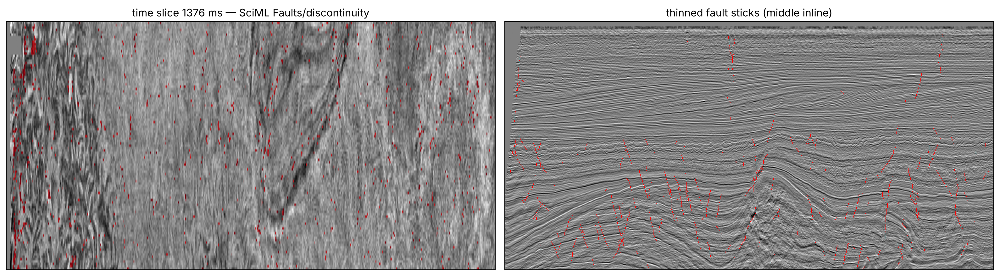

wrote runs/20261120-162245_2D/sciml_prob_faults_discontinuity.sgy
artefacts: ['config.json', 'f3_inline_462_label_free_stats.csv', 'f3_inline_462_sciml_prob.npy', 'fig_F3_inline_462_conventional_vs_sciml.png', 'fig_F3_volume.png', 'fig_benchmark_survey.png', 'fig_confusion_matrices.png', 'fig_conventional_curves.png', 'fig_conventional_training_patches.png', 'fig_error_maps.png', 'fig_metrics_comparison.png', 'fig_pr_and_per_inline.png', 'fig_sciml_curves.png', 'fig_sciml_forward_model.png', 'fig_sciml_training_patches.png', 'improvement_benchmark.csv', 'metrics_benchmark.csv', 'sciml_model.keras', 'sciml_prob_faults_discontinuity.sgy', 'sciml_prob_volume.npy']


In [17]:
def crop_slices():
    c = CROP_3D
    def conv(rng, vals):
        a, b = rng
        if LABEL_INDEXING != "inline_number": return slice(a, b)
        return slice(None if a is None else int(np.searchsorted(vals, a)), None if b is None else int(np.searchsorted(vals, b, side="right")))
    return (slice(*c["t"]), conv(c["il"], GEOM["il_vals"]), conv(c["xl"], GEOM["xl_vals"]))

PROB_VOL = STD_VOL = None
if PREDICT_VOLUME:
    sl = crop_slices(); sub = VOL[sl]; t0 = time.time()
    print("predicting sub-volume (t, il, xl):", sub.shape)
    if NDIM == 3:
        PROB_VOL, STD_VOL = predict_with_uncertainty(sciml, sub, n_mc=min(MC_SAMPLES, 5))
    else:
        set_mc_dropout(sciml, False)
        PROB_VOL = np.stack([sliding_window_predict(sciml, sub[:, i]) for i in range(sub.shape[1])], 1)
    tt = np.arange(NT)[sl[0]]
    PROB_VOL *= tt[:, None, None] >= FIRST_SAFE[sl[1], sl[2]][None]
    print(f"done in {time.time() - t0:.0f}s")
    np.save(os.path.join(RUN_DIR, "sciml_prob_volume.npy"), PROB_VOL.astype(np.float16))
    it = int(np.median(FIRST_SAFE[sl[1], sl[2]])) + (sub.shape[0] - int(np.median(FIRST_SAFE[sl[1], sl[2]]))) // 2
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1, 1]))
    ax[0].imshow(sub[it], cmap="gray", aspect="auto"); ax[0].imshow(np.ma.masked_less(PROB_VOL[it], SYNTH_THR), cmap="Reds", vmin=0, vmax=1, aspect="auto")
    ax[0].set_title(f"time slice {it * GEOM['dt_ms']:.0f} ms — SciML {CLASS_NAME}")
    th = skeletonize(PROB_VOL[:, PROB_VOL.shape[1] // 2] >= SYNTH_THR)
    ax[1].imshow(sub[:, sub.shape[1] // 2], cmap="gray", aspect="auto")
    ax[1].imshow(np.ma.masked_equal(th, 0), cmap="autumn", aspect="auto", interpolation="none"); ax[1].set_title("thinned fault sticks (middle inline)")
    for a in ax: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); savefig("fig_F3_volume.png"); plt.show()

def export_segy(src, dst, cube, crop):
    full = np.zeros((NT, NIL, NXL), np.float32); full[crop] = cube
    shutil.copyfile(src, dst)
    with segyio.open(dst, "r+", ignore_geometry=True) as f:
        ii = np.searchsorted(GEOM["il_vals"], np.asarray(f.attributes(IL_BYTE)[:]))
        xx = np.searchsorted(GEOM["xl_vals"], np.asarray(f.attributes(XL_BYTE)[:]))
        for n in range(f.tracecount): f.trace[n] = np.ascontiguousarray(full[:, ii[n], xx[n]])
    print("wrote", dst)

if EXPORT_SEGY and SEGY_PATH and PROB_VOL is not None:
    export_segy(SEGY_PATH, os.path.join(RUN_DIR, "sciml_prob_faults_discontinuity.sgy"), PROB_VOL, crop_slices())
    if STD_VOL is not None: export_segy(SEGY_PATH, os.path.join(RUN_DIR, "sciml_uncertainty.sgy"), STD_VOL, crop_slices())
print("artefacts:", sorted(os.listdir(RUN_DIR)))

## Notes and limitations
* The benchmark uses the F3 wavelet and noise, but its geology is simulated; numbers quantify the methods under controlled conditions with exact truth. The F3 figure (§12) shows the behaviour on real data; F3 masks (`LABEL_DIR`) turn §12 into a real-data score.
* Conventional ML is reproduced from the original notebook and given more epochs and a tuned threshold than published (its best case).
* "Faults/discontinuity" = faults + small-offset fractures. Unconformities, folds and noise are deliberately labelled *not fault*.
* Every run saves its configuration, histories, models, metric tables and figures in `RUN_DIR`.